In [2]:
import pandas as pd
import numpy as np
import re
import nltk
import string
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

In [3]:
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [4]:
df = pd.read_csv(
    '/content/drive/MyDrive/consumer_complaints_cleaned (1).csv.gz',
    compression='gzip',
    nrows=200000
)

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (200000, 5)


,Consumer complaint narrative,Product,char_count,word_count,sentence_count
0,In accordance with the fair credit reporting a...,"Credit reporting, credit repair services, or o...",793,151,8
1,This is not a duplicate nor is this complaint ...,"Credit reporting, credit repair services, or o...",1233,214,12
2,It has come to my attention. That my personal ...,"Credit reporting, credit repair services, or o...",1342,228,16
3,The Federal Trade Commission Bureau of Consume...,"Credit reporting, credit repair services, or o...",1060,172,7
4,There were several inaccurate personal informa...,"Credit reporting, credit repair services, or o...",179,29,3


In [5]:
df.columns

Index(['Consumer complaint narrative', 'Product', 'char_count', 'word_count',
       'sentence_count'],
      dtype='object')

In [6]:
df.shape

(200000, 5)

In [7]:
df.isnull().sum()

,0
Consumer complaint narrative,0
Product,0
char_count,0
word_count,0
sentence_count,0


In [8]:
df = df[['Consumer complaint narrative', 'Product']].copy()

df.head()

,Consumer complaint narrative,Product
0,In accordance with the fair credit reporting a...,"Credit reporting, credit repair services, or o..."
1,This is not a duplicate nor is this complaint ...,"Credit reporting, credit repair services, or o..."
2,It has come to my attention. That my personal ...,"Credit reporting, credit repair services, or o..."
3,The Federal Trade Commission Bureau of Consume...,"Credit reporting, credit repair services, or o..."
4,There were several inaccurate personal informa...,"Credit reporting, credit repair services, or o..."


In [9]:
df.rename(columns={
    'Consumer complaint narrative': 'text',
    'Product': 'target'
}, inplace=True)

df.head()

,text,target
0,In accordance with the fair credit reporting a...,"Credit reporting, credit repair services, or o..."
1,This is not a duplicate nor is this complaint ...,"Credit reporting, credit repair services, or o..."
2,It has come to my attention. That my personal ...,"Credit reporting, credit repair services, or o..."
3,The Federal Trade Commission Bureau of Consume...,"Credit reporting, credit repair services, or o..."
4,There were several inaccurate personal informa...,"Credit reporting, credit repair services, or o..."


In [10]:
print("Missing Text:", df['text'].isnull().sum())
print("Missing Target:", df['target'].isnull().sum())

Missing Text: 0
Missing Target: 0


In [11]:
print("Duplicate Texts:", df['text'].duplicated().sum())

print("Duplicate Text-Target Pairs:",
      df.duplicated(subset=['text', 'target']).sum())

Duplicate Texts: 0
Duplicate Text-Target Pairs: 0


In [12]:
import re
import html
import pandas as pd
import numpy as np

In [13]:
def clean_text(text):

    if pd.isna(text):
        return ""

    # 1. Convert to string
    text = str(text)

    # 2. Decode HTML entities
    text = html.unescape(text)

    # 3. Convert to lowercase
    text = text.lower()

    # 4. Remove HTML tags
    text = re.sub(r'<[^>]+>', ' ', text)

    # 5. Remove URLs
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)

    # 6. Remove email addresses
    text = re.sub(r'\b[\w.+-]+@[\w.-]+\.[a-zA-Z]{2,}\b', ' ', text)

    # 7. Normalize contractions
    text = re.sub(r"won't", "will not", text)
    text = re.sub(r"can't", "can not", text)
    text = re.sub(r"n't\b", " not", text)
    text = re.sub(r"'re\b", " are", text)
    text = re.sub(r"'ve\b", " have", text)
    text = re.sub(r"'ll\b", " will", text)
    text = re.sub(r"'d\b", " would", text)
    text = re.sub(r"'m\b", " am", text)

    # 8. Preserve decimal numbers
    text = re.sub(r'(?<=\d)\.(?=\d)', 'DECIMALPOINT', text)

    # 9. Remove special characters
    text = re.sub(r'[^a-z0-9\s]', ' ', text)

    # 10. Restore decimal points
    text = text.replace('DECIMALPOINT', '.')

    # 11. Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [15]:
df['cleaned_text'] = df['text'].apply(clean_text)

df[['text', 'cleaned_text']].head(10)

,text,cleaned_text
0,In accordance with the fair credit reporting a...,in accordance with the fair credit reporting a...
1,This is not a duplicate nor is this complaint ...,this is not a duplicate nor is this complaint ...
2,It has come to my attention. That my personal ...,it has come to my attention that my personal i...
3,The Federal Trade Commission Bureau of Consume...,the federal trade commission bureau of consume...
4,There were several inaccurate personal informa...,there were several inaccurate personal informa...
5,"The following creditors, XXXX XXXXXXXX XXXX, a...",the following creditors xxxx xxxxxxxx xxxx and...
6,Hi I am submitting this XXXX XXXX this isn't a...,hi i am submitting this xxxx xxxx this is not ...
7,I am very concerned about the items that are b...,i am very concerned about the items that are b...
8,In accordance with the Fair Credit Reporting A...,in accordance with the fair credit reporting a...
9,Under 15 U.S. Code 1681b Permissible purposes ...,under 15 u s code 1681b permissible purposes o...


In [16]:
for i in range(5):

    print("\nORIGINAL TEXT:")
    print(df['text'].iloc[i])

    print("\nCLEANED TEXT:")
    print(df['cleaned_text'].iloc[i])

    print("-" * 100)


ORIGINAL TEXT:
In accordance with the fair credit reporting act XXXX  account XXXX XXXX # XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX Has violated my rights,15 U.S.C.1681 section 602 A states that I have a right to my privacy. 1 5 U.S.C. 1681 section 602 A section 2 states a consumer reporting company can not furnish an account without my written instructions which I have never given.

CLEANED TEXT:
in accordance with the fair credit reporting act xxxx account xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxx

In [17]:
df['original_char_count'] = df['text'].str.len()

df['cleaned_char_count'] = df['cleaned_text'].str.len()

df['original_word_count'] = df['text'].str.split().str.len()

df['cleaned_word_count'] = df['cleaned_text'].str.split().str.len()

df[['original_char_count',
    'cleaned_char_count',
    'original_word_count',
    'cleaned_word_count']].describe()

,original_char_count,cleaned_char_count,original_word_count,cleaned_word_count
count,200000.000000,200000.000000,200000.000000,200000.000000
mean,1081.242715,1050.068325,194.002980,194.842300
std,1169.601064,1131.619074,207.760852,206.401069
min,4.000000,4.000000,1.000000,1.000000
25%,426.000000,414.000000,76.000000,77.000000
50%,754.000000,733.000000,136.000000,136.000000
75%,1353.000000,1315.000000,244.000000,245.000000
max,31392.000000,31309.000000,6024.000000,6123.000000


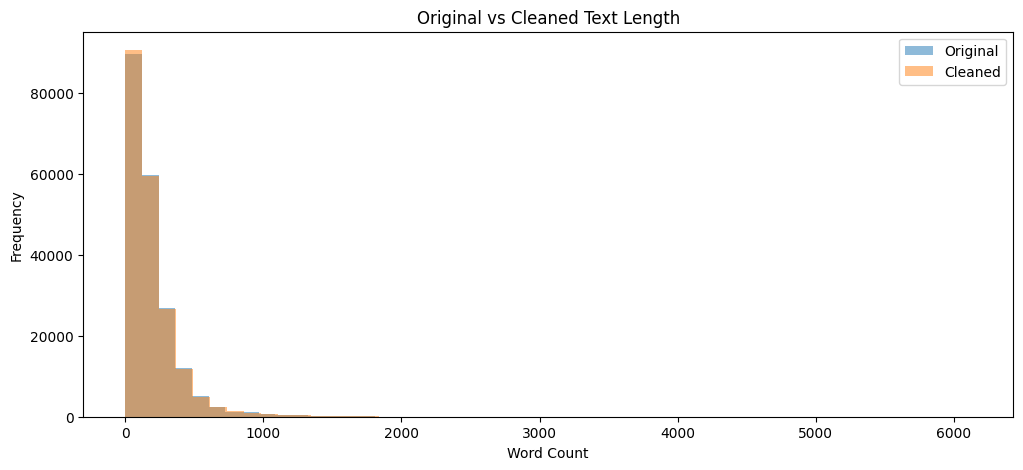

In [18]:
plt.figure(figsize=(12, 5))

plt.hist(df['original_word_count'], bins=50,
         alpha=0.5, label='Original')

plt.hist(df['cleaned_word_count'], bins=50,
         alpha=0.5, label='Cleaned')

plt.xlabel("Word Count")
plt.ylabel("Frequency")
plt.title("Original vs Cleaned Text Length")

plt.legend()
plt.show()

In [19]:
empty_count = (df['cleaned_text'].str.strip() == '').sum()

print("Empty cleaned texts:", empty_count)

Empty cleaned texts: 0


In [20]:
df['original_word_count'] = df['text'].str.split().str.len()

df['cleaned_word_count'] = df['cleaned_text'].str.split().str.len()

df[['original_word_count', 'cleaned_word_count']].describe()

,original_word_count,cleaned_word_count
count,200000.000000,200000.000000
mean,194.002980,194.842300
std,207.760852,206.401069
min,1.000000,1.000000
25%,76.000000,77.000000
50%,136.000000,136.000000
75%,244.000000,245.000000
max,6024.000000,6123.000000


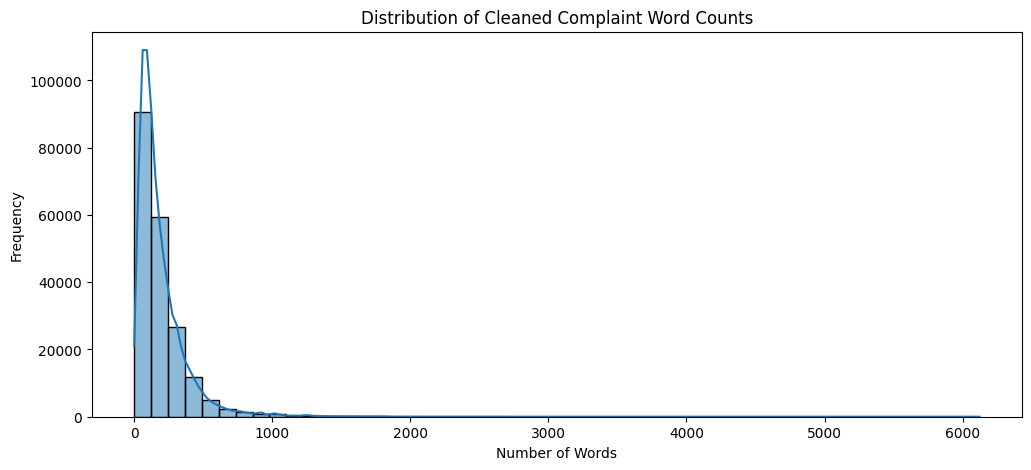

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

sns.histplot(
    df['cleaned_word_count'],
    bins=50,
    kde=True
)

plt.title("Distribution of Cleaned Complaint Word Counts")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

In [22]:
import nltk

nltk.download('stopwords')

from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))

print("Total Stopwords:", len(stop_words))
print(list(stop_words)[:30])

Total Stopwords: 198
['any', 'm', 'before', 'their', 'not', 'ain', 'whom', 'so', 'when', 'it', "they'd", 'am', 'shan', 't', 'which', 'having', 'been', 'has', "he'd", "they've", 'what', 'isn', 'each', 'mustn', 'itself', "it'd", 'than', 'out', "should've", 'against']


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [23]:
negation_words = {
    'no', 'not', 'nor', 'never',
    'neither', 'none', 'cannot'
}

stop_words = stop_words - negation_words

print("Stopwords after preserving negations:", len(stop_words))

Stopwords after preserving negations: 195


In [24]:
def remove_stopwords(text):

    words = text.split()

    filtered_words = [
        word for word in words
        if word not in stop_words
    ]

    return ' '.join(filtered_words)

In [25]:
df['text_no_stopwords'] = df['cleaned_text'].apply(remove_stopwords)

df[['cleaned_text', 'text_no_stopwords']].head()

,cleaned_text,text_no_stopwords
0,in accordance with the fair credit reporting a...,accordance fair credit reporting act xxxx acco...
1,this is not a duplicate nor is this complaint ...,not duplicate nor complaint filed third party ...
2,it has come to my attention that my personal i...,come attention personal information identity c...
3,the federal trade commission bureau of consume...,federal trade commission bureau consumer prote...
4,there were several inaccurate personal informa...,several inaccurate personal information credit...


In [26]:
for i in range(5):

    print("\nCLEANED TEXT:")
    print(df['cleaned_text'].iloc[i])

    print("\nAFTER STOPWORD REMOVAL:")
    print(df['text_no_stopwords'].iloc[i])

    print("=" * 100)


CLEANED TEXT:
in accordance with the fair credit reporting act xxxx account xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx has violated my rights 15 u s c 1681 section 602 a states that i have a right to my privacy 1 5 u s c 1681 section 602 a section 2 states a consumer reporting company can not furnish an account without my written instructions which i have never given

AFTER STOPWORD REMOVAL:
accordance fair credit reporting act xxxx account xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xxxx xx

In [27]:
xxxx_count = df['cleaned_text'].str.count(r'\bxxxx\b').sum()

print("Total xxxx occurrences:", xxxx_count)

Total xxxx occurrences: 2653290


In [33]:
print(
    "Remaining xxxx occurrences:",
    df['text_no_stopwords'].str.count(r'\bx{4,}\b').sum()
)


Remaining xxxx occurrences: 2703183


In [34]:
def clean_text(text):

    if pd.isna(text):
        return ""

    text = html.unescape(str(text)).lower()

    # Remove HTML tags
    text = re.sub(r'<[^>]+>', ' ', text)

    # Remove URLs
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)

    # Remove emails
    text = re.sub(
        r'\b[\w.+-]+@[\w.-]+\.[a-zA-Z]{2,}\b',
        ' ',
        text
    )

    # Expand contractions
    text = re.sub(r"\bcan't\b", "can not", text)
    text = re.sub(r"\bwon't\b", "will not", text)
    text = re.sub(r"n't\b", " not", text)

    # Remove masked placeholders
    text = re.sub(r'\bx{2,}\b', ' ', text)

    # Remove special characters
    text = re.sub(r'[^a-z0-9.\s]', ' ', text)

    # Normalize spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [35]:
df['cleaned_text'] = df['text_no_stopwords'].map(clean_text)

remaining = df['cleaned_text'].str.count(
    r'\bx{2,}\b'
).sum()

print("Remaining placeholders:", remaining)

Remaining placeholders: 0


In [36]:
df

,text,target,cleaned_text,original_char_count,cleaned_char_count,original_word_count,cleaned_word_count,text_no_stopwords
0,In accordance with the fair credit reporting a...,"Credit reporting, credit repair services, or o...",accordance fair credit reporting act account v...,793,787,151,156,accordance fair credit reporting act xxxx acco...
1,This is not a duplicate nor is this complaint ...,"Credit reporting, credit repair services, or o...",not duplicate nor complaint filed third party ...,1233,1212,214,213,not duplicate nor complaint filed third party ...
2,It has come to my attention. That my personal ...,"Credit reporting, credit repair services, or o...",come attention personal information identity c...,1342,1282,228,247,come attention personal information identity c...
3,The Federal Trade Commission Bureau of Consume...,"Credit reporting, credit repair services, or o...",federal trade commission bureau consumer prote...,1060,1043,172,172,federal trade commission bureau consumer prote...
4,There were several inaccurate personal informa...,"Credit reporting, credit repair services, or o...",several inaccurate personal information credit...,179,176,29,29,several inaccurate personal information credit...
...,...,...,...,...,...,...,...,...
199995,This company agreed to delete the account but ...,Debt collection,company agreed delete account keeps sending le...,89,89,14,14,company agreed delete account keeps sending le...
199996,"On XX/XX/XXXX, I discovered that two Chase Qui...","Money transfer, virtual currency, or money ser...",discovered two chase quickpay transactions ini...,2824,2753,509,530,xx xx xxxx discovered two chase quickpay trans...
199997,There is an account that has been listed on my...,"Credit reporting, credit repair services, or o...",account listed consumer report plaza services ...,467,464,91,91,account listed consumer report plaza services ...
199998,On XX/XX/2017 I paid my XX/XX/XXXX property ta...,Mortgage,2017 paid property tax payment directly faxed ...,900,883,168,184,xx xx 2017 paid xx xx xxxx property tax paymen...


# Lemmatization


In [37]:
import nltk

nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('averaged_perceptron_tagger_eng')

from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet
from nltk import pos_tag, word_tokenize

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


In [42]:
import nltk

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('averaged_perceptron_tagger_eng')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


True

In [43]:
lemmatizer = WordNetLemmatizer()

In [44]:
def get_wordnet_pos(tag):

    if tag.startswith('J'):
        return wordnet.ADJ

    elif tag.startswith('V'):
        return wordnet.VERB

    elif tag.startswith('N'):
        return wordnet.NOUN

    elif tag.startswith('R'):
        return wordnet.ADV

    else:
        return wordnet.NOUN

In [45]:
def lemmatize_text(text):

    words = word_tokenize(text)

    tagged_words = pos_tag(words)

    lemmatized_words = []

    for word, tag in tagged_words:

        pos = get_wordnet_pos(tag)

        lemma = lemmatizer.lemmatize(word, pos)

        lemmatized_words.append(lemma)

    return ' '.join(lemmatized_words)

In [46]:
batch_size = 5000

lemmatized_results = []

for start in range(0, len(df), batch_size):

    batch = df['text_no_stopwords'].iloc[
        start:start + batch_size
    ]

    results = batch.map(lemmatize_text)

    lemmatized_results.extend(results.tolist())

    print(f"Processed: {min(start + batch_size, len(df))}/{len(df)}")

df['lemmatized_text'] = lemmatized_results

Processed: 5000/200000
Processed: 10000/200000
Processed: 15000/200000
Processed: 20000/200000
Processed: 25000/200000
Processed: 30000/200000
Processed: 35000/200000
Processed: 40000/200000
Processed: 45000/200000
Processed: 50000/200000
Processed: 55000/200000
Processed: 60000/200000
Processed: 65000/200000
Processed: 70000/200000
Processed: 75000/200000
Processed: 80000/200000
Processed: 85000/200000
Processed: 90000/200000
Processed: 95000/200000
Processed: 100000/200000
Processed: 105000/200000
Processed: 110000/200000
Processed: 115000/200000
Processed: 120000/200000
Processed: 125000/200000
Processed: 130000/200000
Processed: 135000/200000
Processed: 140000/200000
Processed: 145000/200000
Processed: 150000/200000
Processed: 155000/200000
Processed: 160000/200000
Processed: 165000/200000
Processed: 170000/200000
Processed: 175000/200000
Processed: 180000/200000
Processed: 185000/200000
Processed: 190000/200000
Processed: 195000/200000
Processed: 200000/200000


In [48]:
df['lemmatized_text'] = (
    df['lemmatized_text']
    .str.replace(r'\bx{2,}\b', ' ', regex=True, flags=re.IGNORECASE)
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)

In [50]:
df.to_csv('cfpb_preprocessed_200k.csv', index=False)

Final observations
1. Selected 200,000 consumer complaint records to build a manageable NLP dataset.

2. Identified text as the input feature and target (Product) as the classification label.

3. Checked missing values and duplicate records to improve dataset quality.

4. Analyzed complaint character counts and word counts to understand text-length variations.

5. Observed that consumer complaints contain lengthy narratives with financial terminology, legal references, account details and personal information placeholders.

6. Converted all complaint text into lowercase to maintain consistency.

7. Removed HTML tags, URLs, email addresses and unnecessary special characters.

8. Removed masked placeholders such as xxxx because they do not provide meaningful complaint-category information.

9. Preserved meaningful numbers and financial terms because they may help distinguish complaint categories.

10. Preserved negation words such as not, never, no and nor during stopword removal to avoid changing sentence meaning.

11. Observed that stopword removal reduced the number of words while retaining important complaint-related information.

12. Applied lemmatization to convert words into their dictionary base forms, reducing variations of words.

13. Maintained separate text representations to compare the impact of different preprocessing techniques during model development.

14. Saved the preprocessed dataset in Parquet format for efficient storage and future experiments.